Import the libraries and set the image size, batch size, number of epochs, random seed, and output folder.

In [3]:
from pathlib import Path
import csv
import random
import numpy as np
import tensorflow as tf


ROOT = Path(r"C:\Users\Brandon\PycharmProjects\Catsndogs")
DATA = ROOT / "dataset"
OUT = ROOT / "assignment_results"

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
EPOCHS = 10
SEED = 42

OUT.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASSES = ["cat", "dog"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}


Create fixed validation and test subsets so each experiment is evaluated on the same images.

In [4]:
def make_subset(source, destination, per_class=250):
    source = DATA / source
    destination = DATA / destination

    if destination.exists():
        import shutil
        shutil.rmtree(destination)

    for cls in CLASSES:
        files = sorted(
            p for p in (source / cls).iterdir()
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        )

        if len(files) < per_class:
            raise ValueError(f"Not enough images in {source / cls}")

        # Use a stable seed for reproducible selection.
        stable_seed = SEED + sum(
            ord(c) for c in f"{source.name}_{cls}"
        )
        rng = random.Random(stable_seed)
        chosen = rng.sample(files, per_class)

        target = destination / cls
        target.mkdir(parents=True)

        for file in chosen:
            import shutil
            shutil.copy2(file, target / file.name)

Load images from class folders. VGG16 images are preprocessed for the pretrained network.

In [5]:
def load_data(folder, training=False, pretrained=False):
    ds = tf.keras.utils.image_dataset_from_directory(
        folder,
        class_names=CLASSES,
        label_mode="binary",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=training,
        seed=SEED
    )

    if pretrained:
        ds = ds.map(
            lambda x, y: (
                tf.keras.applications.vgg16.preprocess_input(x),
                y
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    return ds.prefetch(tf.data.AUTOTUNE)


Build a CNN that learns image features from the training images.

In [6]:
def build_scratch_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(150, 150, 3)),
        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="rmsprop",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


Build VGG16 with ImageNet weights. Freeze its convolutional base and train a new classification head.

In [7]:
def build_pretrained_vgg16():
    base = tf.keras.applications.VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(150, 150, 3)
    )
    base.trainable = False

    inputs = tf.keras.Input(shape=(150, 150, 3))
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer="rmsprop",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


Train each model, save the checkpoint with the lowest validation loss, evaluate it on the test set, and save the results.

In [8]:
def run_experiment(model_type, sample_name, train_folder, train_count):
    print(f"\n{'=' * 55}")
    print(f"{model_type} | {sample_name} | {train_count} training images")
    print("=" * 55)

    pretrained = model_type == "pretrained_vgg16"

    train_ds = load_data(train_folder, True, pretrained)
    val_ds = load_data(DATA / "val_500", False, pretrained)
    test_ds = load_data(DATA / "test_500", False, pretrained)

    model = (
        build_pretrained_vgg16()
        if pretrained else build_scratch_cnn()
    )

    name = f"{model_type}_{sample_name}"
    checkpoint = OUT / f"{name}_best.keras"

    callback = tf.keras.callbacks.ModelCheckpoint(
        str(checkpoint),
        monitor="val_loss",
        save_best_only=True,
        mode="min"
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[callback]
    )

    # Evaluate the checkpoint with the lowest validation loss.
    best_model = tf.keras.models.load_model(checkpoint)
    test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=0)

    best_epoch = int(np.argmin(history.history["val_loss"]))

    result = {
        "model": model_type,
        "training_images": train_count,
        "best_epoch": best_epoch + 1,
        "best_validation_accuracy":
            history.history["val_accuracy"][best_epoch],
        "best_validation_loss":
            history.history["val_loss"][best_epoch],
        "test_accuracy": test_accuracy,
        "test_loss": test_loss
    }

    with open(OUT / f"{name}_history.csv", "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "epoch", "accuracy", "loss",
            "val_accuracy", "val_loss"
        ])

        for i in range(len(history.history["loss"])):
            writer.writerow([
                i + 1,
                history.history["accuracy"][i],
                history.history["loss"][i],
                history.history["val_accuracy"][i],
                history.history["val_loss"][i]
            ])

    print("\nTEST RESULTS")
    print(f"Test accuracy: {test_accuracy:.4f}")
    print(f"Test loss:     {test_loss:.4f}")

    return result


Check the expected dataset folders, create the 5,000-image sample, and define all six experiments.

In [9]:
def main():
    # Existing folders should contain 500 images per class
    # in train_small and 11,500 per class in train_full.
    for folder in ["train_small", "train_full", "val", "test"]:
        for cls in CLASSES:
            path = DATA / folder / cls
            if not path.exists():
                raise FileNotFoundError(f"Missing folder: {path}")

    # Make 500-image validation and test sets: 250 cats + 250 dogs.
    make_subset("val", "val_500")
    make_subset("test", "test_500")

    # Create a reproducible 5,000-image sample: 2,500 per class.
    import shutil
    mid = DATA / "train_mid"
    if mid.exists():
        shutil.rmtree(mid)

    for cls in CLASSES:
        files = sorted(
            p for p in (DATA / "train_full" / cls).iterdir()
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        )
        rng = random.Random(SEED + (1 if cls == "dog" else 0))
        chosen = rng.sample(files, 2500)

        target = mid / cls
        target.mkdir(parents=True)

        for file in chosen:
            shutil.copy2(file, target / file.name)

    samples = [
        ("1000", DATA / "train_small", 1000),
        ("5000", mid, 5000),
        ("23000", DATA / "train_full", 23000)
    ]

    results = []

    for model_type in ["scratch_cnn", "pretrained_vgg16"]:
        for sample_name, folder, count in samples:
            result = run_experiment(
                model_type, sample_name, folder, count
            )
            results.append(result)

            # Save results after each run in case a later run fails.
            with open(OUT / "summary.csv", "w", newline="") as f:
                writer = csv.DictWriter(
                    f, fieldnames=list(results[0].keys())
                )
                writer.writeheader()
                writer.writerows(results)

    print("\nALL EXPERIMENTS FINISHED")
    print(f"Results saved to: {OUT / 'summary.csv'}")


if __name__ == "__main__":
    main()



scratch_cnn | 1000 | 1000 training images
Found 1000 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Epoch 1/10


C:\Users\Brandon\PycharmProjects\Catsndogs\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.4990 - loss: 0.7352 - val_accuracy: 0.5160 - val_loss: 0.6926
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.5370 - loss: 0.6960 - val_accuracy: 0.5580 - val_loss: 0.6841
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.5560 - loss: 0.6850 - val_accuracy: 0.5640 - val_loss: 0.6854
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.6000 - loss: 0.6745 - val_accuracy: 0.5640 - val_loss: 0.6743
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.6220 - loss: 0.6454 - val_accuracy: 0.5640 - val_loss: 0.6504
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.6220 - loss: 0.6498 - val_accuracy: 0.6720 - val_loss: 0.6248
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.6810 - loss: 0.6047 - val_accuracy: 0.5260 - val_loss: 1.0164
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.6680 - loss: 0.6135 - val_accuracy: 0.6980 - val_loss: 0.

Run the six experiments. This cell trains the models and writes checkpoints and per-epoch history files.

Load the saved results and compare test accuracy and test loss.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

results_path = OUT / "summary.csv"
results = pd.read_csv(results_path)
display(results)


,model,training_images,best_epoch,best_validation_accuracy,best_validation_loss,test_accuracy,test_loss
0,scratch_cnn,1000,8,0.698,0.603547,0.660,0.626843
1,scratch_cnn,5000,5,0.764,0.497855,0.782,0.505062
2,scratch_cnn,23000,3,0.830,0.365147,0.814,0.376898
3,pretrained_vgg16,1000,5,0.970,0.067114,0.944,0.310715
4,pretrained_vgg16,5000,3,0.980,0.063911,0.944,0.208096
5,pretrained_vgg16,23000,4,0.982,0.055200,0.952,0.203497


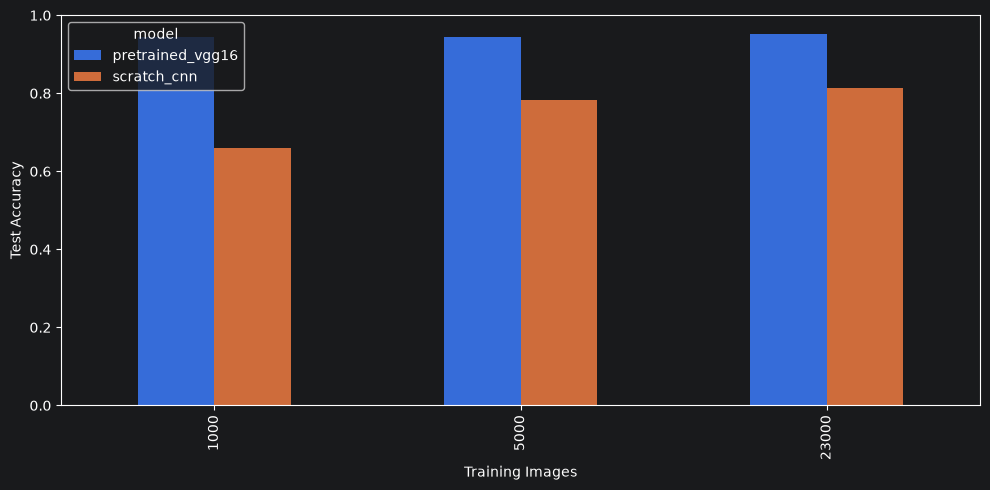

In [11]:
accuracy_plot = results.pivot(
    index="training_images", columns="model", values="test_accuracy"
)
accuracy_plot.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Test Accuracy")
plt.xlabel("Training Images")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


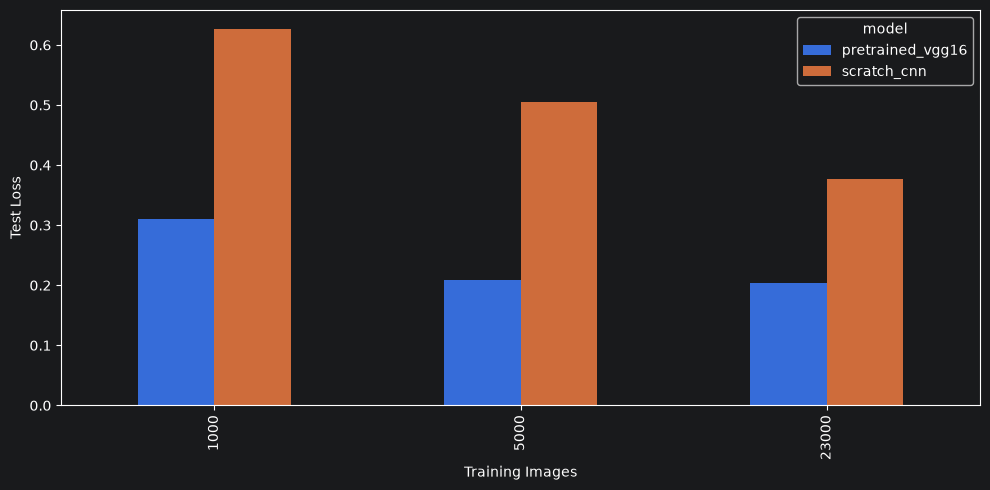

In [12]:
loss_plot = results.pivot(
    index="training_images", columns="model", values="test_loss"
)
loss_plot.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Test Loss")
plt.xlabel("Training Images")
plt.tight_layout()
plt.show()
